# Retail Driver Analysis — Store Sales and Promotion Performance

## Business Objective

Investigate differences in sales performance and promotional
activity across the retailer's 54 stores.

## Business Questions

1. Which stores generate the highest sales?
2. How concentrated are sales among stores?
3. How frequently does promotional activity occur at each store?
4. Are stores with greater promotional activity associated
   with higher sales?
5. How can these findings inform retail forecasting?

## Analysis Period

January 2013 – July 2017 (55 complete months).

## Analytical Limitations

Sales are aggregated by date, store and product family.

Promotion activity is measured using the count of promoted
items, not discount percentages.

Observed associations do not establish causality.

In [1]:
from pathlib import Path
import pandas as pd

# Locate the project root.
PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "data" / "processed").exists():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("Project data folder not found.")
    PROJECT_ROOT = PROJECT_ROOT.parent

# Load required data.
sales = pd.read_csv(
    PROJECT_ROOT / "data/processed/train_standardized.csv",
    usecols=[
        "date",
        "store_nbr",
        "family",
        "sales",
        "onpromotion"
    ],
    parse_dates=["date"]
)

# Use the same complete-month analysis period.
sales = sales.loc[
    (sales["date"] >= "2013-01-01")
    & (sales["date"] < "2017-08-01")
].copy()

print("Records:", len(sales))
print("Stores:", sales["store_nbr"].nunique())
print("Families:", sales["family"].nunique())
print("Total sales:", round(sales["sales"].sum(), 2))

sales.head()

Records: 2974158
Stores: 54
Families: 33
Total sales: 1061211629.26


,date,store_nbr,family,sales,onpromotion
0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,2013-01-01,1,BABY CARE,0.0,0
2,2013-01-01,1,BEAUTY,0.0,0
3,2013-01-01,1,BEVERAGES,0.0,0
4,2013-01-01,1,BOOKS,0.0,0


## 1. Store-Level Sales Performance

### Business Objective

Identify the highest-performing stores and understand
how total sales are distributed across 54 stores.

### KPIs

1. Total Sales
2. Number of Sales Records
3. Average Sales per Store–Family–Day Record
4. Sales Contribution %
5. Store Sales Rank
6. Cumulative Sales Contribution %

### Business Importance

Store-level analysis helps identify major revenue contributors,
understand sales concentration, and prioritize store-level
forecasting and operational planning.

### Analytical Limitation

Average sales per record is not average transaction value.
The dataset contains aggregated store–family–day observations,
not individual customer transactions.

In [2]:
# Aggregate sales performance by store.
store_performance = (
    sales.groupby("store_nbr", as_index=False)
    .agg(
        total_sales=("sales", "sum"),
        records=("sales", "size"),
        average_sales_per_record=("sales", "mean"),
        active_families=("family", "nunique")
    )
)

# Calculate each store's sales contribution.
total_sales = store_performance["total_sales"].sum()

store_performance["sales_share_pct"] = (
    store_performance["total_sales"]
    / total_sales * 100
)

# Rank stores by total sales.
store_performance = (
    store_performance
    .sort_values(
        ["total_sales", "store_nbr"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

store_performance["sales_rank"] = (
    store_performance.index + 1
)

# Calculate cumulative contribution.
store_performance["cumulative_sales_share_pct"] = (
    store_performance["sales_share_pct"].cumsum()
)

display(store_performance.head(10).round(2))

,store_nbr,total_sales,records,average_sales_per_record,active_families,sales_share_pct,sales_rank,cumulative_sales_share_pct
0,44,61473176.90,55077,1116.13,33,5.79,1,5.79
1,45,53908427.30,55077,978.78,33,5.08,2,10.87
2,47,50404806.72,55077,915.17,33,4.75,3,15.62
3,3,49978015.41,55077,907.42,33,4.71,4,20.33
4,49,42937184.70,55077,779.58,33,4.05,5,24.38
5,46,41469574.72,55077,752.94,33,3.91,6,28.29
6,48,35557559.90,55077,645.60,33,3.35,7,31.64
7,51,32569612.53,55077,591.35,33,3.07,8,34.71
8,8,30190183.66,55077,548.15,33,2.84,9,37.55
9,50,28347785.81,55077,514.69,33,2.67,10,40.22


## 2. Store Sales Validation

### Validation Objectives

- Confirm all 54 stores are represented.
- Reconcile aggregated store sales with the source dataset.
- Confirm all source records are included.
- Confirm store sales contribution percentages sum to 100%.
- Confirm store ranks are unique.

These checks help prevent misleading store-performance reporting.

In [3]:
# Check store count.
assert len(store_performance) == 54

# Reconcile total sales.
assert abs(
    store_performance["total_sales"].sum()
    - sales["sales"].sum()
) < 0.01

# Reconcile record counts.
assert store_performance["records"].sum() == len(sales)

# Validate sales contributions.
assert abs(
    store_performance["sales_share_pct"].sum() - 100
) < 0.000001

# Validate store rankings.
assert store_performance["sales_rank"].is_unique

print("All store-level sales validation checks passed.")

print(
    "Top 5 store sales contribution (%):",
    round(
        store_performance.head(5)["sales_share_pct"].sum(),
        2
    )
)

print(
    "Top 10 store sales contribution (%):",
    round(
        store_performance.head(10)["sales_share_pct"].sum(),
        2
    )
)

All store-level sales validation checks passed.
Top 5 store sales contribution (%): 24.38
Top 10 store sales contribution (%): 40.22


## 3. Top 10 Stores by Total Sales

### Business Question

Which stores generate the highest total sales during the
55-month analysis period?

### Visualization

A horizontal bar chart ranks the ten highest-selling stores.

### Business Importance

This chart helps stakeholders identify major revenue-contributing
stores and prioritize further operational and forecasting analysis.

### Limitation

Total sales alone does not measure profitability, efficiency,
store size, or customer satisfaction.

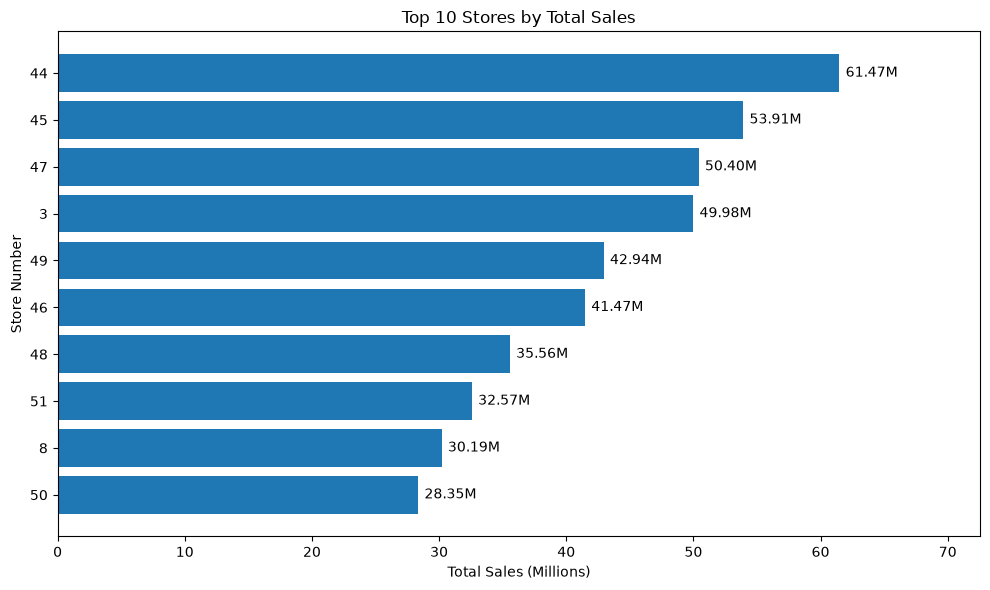

In [4]:
import matplotlib.pyplot as plt

# Select the top 10 stores.
top_10_stores = store_performance.head(10).copy()

# Convert sales to millions for easier reading.
top_10_stores["sales_millions"] = (
    top_10_stores["total_sales"] / 1_000_000
)

# Create horizontal bar chart.
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    top_10_stores["store_nbr"].astype(str),
    top_10_stores["sales_millions"]
)

# Show highest-selling store at the top.
ax.invert_yaxis()

ax.set_title("Top 10 Stores by Total Sales")
ax.set_xlabel("Total Sales (Millions)")
ax.set_ylabel("Store Number")

# Add sales labels.
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}M",
        va="center"
    )

ax.set_xlim(
    0,
    top_10_stores["sales_millions"].max() * 1.18
)

plt.tight_layout()
plt.show()

## 4. Store-Level Promotion Activity

### Business Objective

Measure how frequently promotional activity appears
in each store's sales records.

### KPIs

1. Total Sales
2. Total Records
3. Promotional Records
4. Promotion Record Share %
5. Total Promoted-Item Counts

### Analytical Limitation

Promotion Record Share measures the percentage of
store–family–day records with at least one promoted item.

It is not the percentage of transactions receiving
a discount or the percentage of sales caused by promotions.

In [5]:
# Create a binary indicator for observed promotion activity.
sales["has_promotion"] = sales["onpromotion"] > 0

# Calculate promotion activity by store.
store_promotion = (
    sales.groupby("store_nbr", as_index=False)
    .agg(
        total_sales=("sales", "sum"),
        total_records=("sales", "size"),
        promotional_records=("has_promotion", "sum"),
        total_promoted_item_counts=("onpromotion", "sum")
    )
)

# Percentage of records containing promotional activity.
store_promotion["promotion_record_share_pct"] = (
    store_promotion["promotional_records"]
    / store_promotion["total_records"]
    * 100
)

# Rank stores by promotion record share.
store_promotion = (
    store_promotion
    .sort_values(
        "promotion_record_share_pct",
        ascending=False
    )
    .reset_index(drop=True)
)

display(store_promotion.head(10).round(2))

,store_nbr,total_sales,total_records,promotional_records,total_promoted_item_counts,promotion_record_share_pct
0,46,41469574.72,55077,14867,187302,26.99
1,48,35557559.90,55077,14752,182394,26.78
2,47,50404806.72,55077,14477,189283,26.29
3,45,53908427.30,55077,14218,188004,25.81
4,44,61473176.90,55077,13946,188904,25.32
5,50,28347785.81,55077,13942,170994,25.31
6,6,24942626.08,55077,13709,166958,24.89
7,49,42937184.70,55077,13606,181279,24.70
8,3,49978015.41,55077,13508,174133,24.53
9,38,18675424.53,55077,13138,144686,23.85


## 5. Store Promotion Data Validation

### Objective

Validate store-level promotional activity before
interpreting relationships between promotions and sales.

### Validation Rules

1. All 54 stores must be represented.
2. Store record counts must reconcile to the source.
3. Store sales must reconcile to the source.
4. Promotional record counts must reconcile.
5. Promotion record shares must be between 0% and 100%.
6. Promoted-item counts must reconcile.

In [6]:
# Validate number of stores.
assert len(store_promotion) == 54

# Validate source record reconciliation.
assert (
    store_promotion["total_records"].sum()
    == len(sales)
)

# Validate sales reconciliation.
assert abs(
    store_promotion["total_sales"].sum()
    - sales["sales"].sum()
) < 0.01

# Validate promotional record counts.
assert (
    store_promotion["promotional_records"].sum()
    == sales["has_promotion"].sum()
)

# Validate promotion share boundaries.
assert store_promotion[
    "promotion_record_share_pct"
].between(0, 100).all()

# Validate promoted-item count reconciliation.
assert (
    store_promotion["total_promoted_item_counts"].sum()
    == sales["onpromotion"].sum()
)

print("All store promotion validation checks passed.")

print(
    "Overall promotion record share (%):",
    round(sales["has_promotion"].mean() * 100, 2)
)

print(
    "Highest promotion share store:",
    store_promotion.iloc[0]["store_nbr"]
)

print(
    "Lowest promotion share store:",
    store_promotion.iloc[-1]["store_nbr"]
)

All store promotion validation checks passed.
Overall promotion record share (%): 20.16
Highest promotion share store: 46.0
Lowest promotion share store: 52.0


## 6. Relationship Between Promotion Activity and Store Sales

### Business Question

Do stores with higher promotion record shares tend
to generate higher total sales?

### Analytical Method

- Scatter plot
- Pearson correlation coefficient

### Interpretation

A positive correlation indicates that higher promotion
record shares tend to occur alongside higher store sales.

A negative correlation indicates the opposite.

Correlation does not establish causation.

Store size, customer traffic, product mix, and other
factors may influence the relationship.

Pearson correlation: 0.728


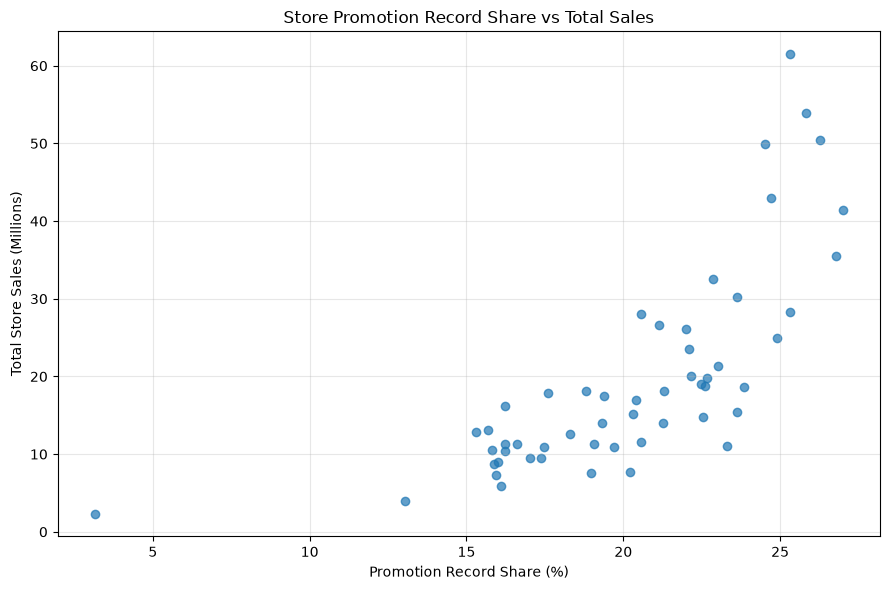

In [7]:
import matplotlib.pyplot as plt

# Calculate Pearson correlation.
correlation = store_promotion[
    ["promotion_record_share_pct", "total_sales"]
].corr().iloc[0, 1]

print(
    "Pearson correlation:",
    round(correlation, 3)
)

# Create scatter plot.
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    store_promotion["promotion_record_share_pct"],
    store_promotion["total_sales"] / 1_000_000,
    alpha=0.7
)

ax.set_title(
    "Store Promotion Record Share vs Total Sales"
)

ax.set_xlabel("Promotion Record Share (%)")
ax.set_ylabel("Total Store Sales (Millions)")

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Store Promotion Outlier Investigation

### Business Objective

Investigate stores with unusually low or high promotional
activity and evaluate their influence on the relationship
between promotion record share and total sales.

### Investigation Questions

1. Which stores have the lowest promotion record share?
2. How does Store 52 compare with other stores?
3. Does Store 52 have fewer sales records?
4. How sensitive is the Pearson correlation to Store 52?

### Analytical Principle

An unusual observation is not automatically a data error.

We must investigate before excluding any store.

In [8]:
# Identify the 10 stores with the lowest promotion shares.
lowest_promotion_stores = (
    store_promotion
    .sort_values("promotion_record_share_pct")
    .head(10)
)

display(lowest_promotion_stores.round(2))

,store_nbr,total_sales,total_records,promotional_records,total_promoted_item_counts,promotion_record_share_pct
53,52,2352499.52,55077,1738,27859,3.16
52,22,3978367.64,55077,7185,96750,13.05
51,19,12909472.50,55077,8433,108911,15.31
50,18,13106599.68,55077,8631,130302,15.67
49,12,10545590.64,55077,8716,114850,15.83
48,42,8776438.88,55077,8743,122137,15.87
47,30,7282688.39,55077,8780,100543,15.94
46,21,9036245.51,55077,8821,140287,16.02
45,32,5873540.70,55077,8863,87743,16.09
44,43,16144472.52,55077,8936,120913,16.22


In [9]:
# Original correlation: all 54 stores.
correlation_all = store_promotion[
    ["promotion_record_share_pct", "total_sales"]
].corr().iloc[0, 1]

# Sensitivity analysis: exclude Store 52 temporarily.
store_without_52 = store_promotion.loc[
    store_promotion["store_nbr"] != 52
].copy()

correlation_without_52 = store_without_52[
    ["promotion_record_share_pct", "total_sales"]
].corr().iloc[0, 1]

print("Correlation — All stores:",
      round(correlation_all, 3))

print("Correlation — Excluding Store 52:",
      round(correlation_without_52, 3))

print("Number of stores — All:",
      len(store_promotion))

print("Number of stores — Without Store 52:",
      len(store_without_52))

print(
    "Correlation change:",
    round(correlation_without_52 - correlation_all, 3)
)

Correlation — All stores: 0.728
Correlation — Excluding Store 52: 0.767
Number of stores — All: 54
Number of stores — Without Store 52: 53
Correlation change: 0.039


## 8. Store 52 Data Quality Investigation

### Objective

Determine whether Store 52's unusually low promotional
activity is associated with missing or invalid source data.

### Validation Checks

1. Missing sales values
2. Missing promotion counts
3. Negative promotion counts
4. Date coverage
5. Number of product families
6. Percentage of records with positive sales

### Decision Rule

Retain valid observations, even when their business
performance differs substantially from other stores.

In [10]:
# Isolate Store 52.
store_52 = sales.loc[
    sales["store_nbr"] == 52
].copy()

# Calculate quality and coverage metrics.
store_52_validation = {
    "total_records": len(store_52),
    "missing_sales": store_52["sales"].isna().sum(),
    "missing_promotion": store_52["onpromotion"].isna().sum(),
    "negative_promotion": (
        store_52["onpromotion"] < 0
    ).sum(),
    "first_date": store_52["date"].min(),
    "last_date": store_52["date"].max(),
    "unique_families": store_52["family"].nunique(),
    "positive_sales_share_pct": round(
        (store_52["sales"] > 0).mean() * 100, 2
    ),
    "promotion_record_share_pct": round(
        (store_52["onpromotion"] > 0).mean() * 100, 2
    )
}

display(
    pd.DataFrame(
        store_52_validation.items(),
        columns=["Metric", "Value"]
    )
)

# Check basic source quality.
assert store_52["sales"].notna().all()
assert store_52["onpromotion"].notna().all()
assert (store_52["onpromotion"] >= 0).all()

print("Store 52 basic data quality checks passed.")

,Metric,Value
0,total_records,55077
1,missing_sales,0
2,missing_promotion,0
3,negative_promotion,0
4,first_date,2013-01-01 00:00:00
5,last_date,2017-07-31 00:00:00
6,unique_families,33
7,positive_sales_share_pct,5.7
8,promotion_record_share_pct,3.16


Store 52 basic data quality checks passed.


## 9. Store 52 Sales Activity Over Time

### Business Question

Has Store 52 experienced consistently low sales activity,
or did it begin generating sales later than other stores?

### Analytical Method

Aggregate Store 52 sales by month and calculate:

1. Monthly total sales
2. Monthly positive-sales record counts
3. Monthly promotional record counts

### Business Importance

This investigation helps distinguish persistent low sales
activity from changes in store operations over time.

### Limitation

The first observed sale does not necessarily represent
the official store opening date.

In [13]:
# Create monthly reporting periods.
store_52["month"] = (
    store_52["date"].dt.to_period("M")
)

# Aggregate Store 52 by month.
store_52_monthly = (
    store_52.groupby("month", as_index=False)
    .agg(
        total_sales=("sales", "sum"),
        total_records=("sales", "size"),
        positive_sales_records=(
            "sales",
            lambda x: (x > 0).sum()
        ),
        promotional_records=(
            "onpromotion",
            lambda x: (x > 0).sum()
        )
    )
)

# Calculate monthly activity percentages.
store_52_monthly["positive_sales_share_pct"] = (
    store_52_monthly["positive_sales_records"]
    / store_52_monthly["total_records"] * 100
)

store_52_monthly["promotion_share_pct"] = (
    store_52_monthly["promotional_records"]
    / store_52_monthly["total_records"] * 100
)

print("Monthly records:", len(store_52_monthly))

print("\nFirst 10 months:")
display(
    store_52_monthly.head(10).round({
        "total_sales": 2,
        "positive_sales_share_pct": 2,
        "promotion_share_pct": 2
    })
)

print("\nLast 10 months:")
display(
    store_52_monthly.tail(10).round({
        "total_sales": 2,
        "positive_sales_share_pct": 2,
        "promotion_share_pct": 2
    })
)

Monthly records: 55

First 10 months:


,month,total_sales,total_records,positive_sales_records,promotional_records,positive_sales_share_pct,promotion_share_pct
0,2013-01,0.0,1023,0,0,0.0,0.0
1,2013-02,0.0,924,0,0,0.0,0.0
2,2013-03,0.0,1023,0,0,0.0,0.0
3,2013-04,0.0,990,0,0,0.0,0.0
4,2013-05,0.0,1023,0,0,0.0,0.0
5,2013-06,0.0,990,0,0,0.0,0.0
6,2013-07,0.0,1023,0,0,0.0,0.0
7,2013-08,0.0,1023,0,0,0.0,0.0
8,2013-09,0.0,990,0,0,0.0,0.0
9,2013-10,0.0,1023,0,0,0.0,0.0



Last 10 months:


,month,total_sales,total_records,positive_sales_records,promotional_records,positive_sales_share_pct,promotion_share_pct
45,2016-10,0.00,1023,0,0,0.00,0.00
46,2016-11,0.00,990,0,0,0.00,0.00
47,2016-12,0.00,990,0,0,0.00,0.00
48,2017-01,0.00,1023,0,0,0.00,0.00
49,2017-02,0.00,924,0,0,0.00,0.00
50,2017-03,0.00,1023,0,0,0.00,0.00
51,2017-04,295182.26,990,338,213,34.14,21.52
52,2017-05,710301.33,1023,952,592,93.06,57.87
53,2017-06,627326.97,990,915,473,92.42,47.78
54,2017-07,719688.96,1023,933,460,91.20,44.97


In [15]:
positive_sales_dates = store_52.loc[
    store_52["sales"] > 0, "date"
]

if not positive_sales_dates.empty:
    print(
        "First observed positive-sales date:",
        positive_sales_dates.min().date()
    )
else:
    print("No positive sales observed.")

print(
    "Months with positive total sales:",
    (store_52_monthly["total_sales"] > 0).sum()
)

print(
    "Months with zero total sales:",
    (store_52_monthly["total_sales"] == 0).sum()
)

First observed positive-sales date: 2017-04-20
Months with positive total sales: 4
Months with zero total sales: 51


In [16]:
# Find first observed positive-sales date.
first_positive_date = store_52.loc[
    store_52["sales"] > 0,
    "date"
].min()

# Find first observed promotional activity date.
first_promotion_date = store_52.loc[
    store_52["onpromotion"] > 0,
    "date"
].min()

print("First positive-sales date:", first_positive_date)
print("First promotion date:", first_promotion_date)

# Count months with positive total sales.
active_months = (
    store_52_monthly["total_sales"] > 0
).sum()

zero_sales_months = (
    store_52_monthly["total_sales"] == 0
).sum()

print("Months with positive sales:", active_months)
print("Months with zero sales:", zero_sales_months)

First positive-sales date: 2017-04-20 00:00:00
First promotion date: 2017-04-21 00:00:00
Months with positive sales: 4
Months with zero sales: 51


## 10. Active-Month Adjusted Store Performance

### Business Objective

Compare stores while accounting for differences in
observed sales activity periods.

### KPIs

1. Total Sales
2. Observed Active Months
3. Average Sales per Active Month
4. Promotion Record Share During Active Months

### Definition

An observed active month is a month in which a store
generates positive total sales.

### Limitations

An active month does not necessarily represent a full
calendar month of operations.

The first positive-sales month may be a partial month.

These metrics are descriptive and do not establish
official store opening dates.

In [17]:
# Create month identifier.
sales["month"] = sales["date"].dt.to_period("M")

# Calculate monthly sales for each store.
store_monthly = (
    sales.groupby(["store_nbr", "month"], as_index=False)
    .agg(
        monthly_sales=("sales", "sum"),
        total_records=("sales", "size"),
        promotional_records=("has_promotion", "sum")
    )
)

# Identify months with positive total sales.
store_monthly["is_active_month"] = (
    store_monthly["monthly_sales"] > 0
)

# Keep only observed active months.
active_store_monthly = store_monthly.loc[
    store_monthly["is_active_month"]
].copy()

# Aggregate active-month performance.
active_store_performance = (
    active_store_monthly.groupby(
        "store_nbr", as_index=False
    )
    .agg(
        observed_active_months=("month", "nunique"),
        sales_during_active_months=("monthly_sales", "sum"),
        active_month_records=("total_records", "sum"),
        promotional_records_active=(
            "promotional_records", "sum"
        )
    )
)

# Calculate average sales per active month.
active_store_performance["avg_sales_per_active_month"] = (
    active_store_performance["sales_during_active_months"]
    / active_store_performance["observed_active_months"]
)

# Calculate promotion share during active months.
active_store_performance["promotion_share_active_pct"] = (
    active_store_performance["promotional_records_active"]
    / active_store_performance["active_month_records"]
    * 100
)

display(
    active_store_performance.loc[
        active_store_performance["store_nbr"].isin(
            [44, 45, 46, 52]
        )
    ].round(2)
)

,store_nbr,observed_active_months,sales_during_active_months,active_month_records,promotional_records_active,avg_sales_per_active_month,promotion_share_active_pct
43,44,55,61473176.90,55077,13946,1117694.13,25.32
44,45,55,53908427.30,55077,14218,980153.22,25.81
45,46,55,41469574.72,55077,14867,753992.27,26.99
51,52,4,2352499.52,4026,1738,588124.88,43.17


## 11. Active-Month Adjusted Correlation Analysis

### Business Question

Does the relationship between store promotional activity
and sales performance change when we account for differences
in observed sales-active months?

### Comparison

Original analysis:
- Promotion record share across the entire dataset
- Total store sales across 55 months

Adjusted analysis:
- Promotion record share during sales-active months
- Average sales per observed active month

### Important Limitation

The adjusted analysis improves comparability but does
not fully control for partial months, store characteristics,
product mix, seasonality, or other confounding factors.

Correlation does not establish causation.

In [18]:
# Recalculate the original correlation.
original_corr = store_promotion[
    ["promotion_record_share_pct", "total_sales"]
].corr().iloc[0, 1]

# Calculate active-month-adjusted correlation.
adjusted_corr = active_store_performance[
    [
        "promotion_share_active_pct",
        "avg_sales_per_active_month"
    ]
].corr().iloc[0, 1]

# Compare results.
correlation_comparison = pd.DataFrame({
    "Method": [
        "Original: Full History",
        "Adjusted: Active Months"
    ],
    "Pearson Correlation": [
        original_corr,
        adjusted_corr
    ]
})

display(correlation_comparison.round(3))

print(
    "Correlation change:",
    round(adjusted_corr - original_corr, 3)
)

print(
    "Stores included:",
    len(active_store_performance)
)

,Method,Pearson Correlation
0,Original: Full History,0.728
1,Adjusted: Active Months,0.397


Correlation change: -0.33
Stores included: 54


In [19]:
# Confirm the original correlation is reproduced.
assert abs(original_corr - 0.728) < 0.001

# Confirm all 54 stores are represented.
assert len(active_store_performance) == 54

# Validate the active-month performance metrics.
assert (
    active_store_performance["observed_active_months"] > 0
).all()

assert active_store_performance[
    "promotion_share_active_pct"
].between(0, 100).all()

# Reconcile source and monthly sales.
assert abs(
    store_monthly["monthly_sales"].sum()
    - sales["sales"].sum()
) < 0.01

# Check correlation is defined.
assert pd.notna(adjusted_corr)

print("Active-month correlation validation passed.")

Active-month correlation validation passed.


## 12. Business Insights — Promotion and Store Activity

### Key Findings

1. The original Pearson correlation between store promotion
   record share and total sales was +0.728.

2. After adjusting for observed sales-active months,
   the correlation decreased to +0.397.

3. Store 52 had 51 months with zero recorded sales.
   Its first observed positive sale occurred on April 20, 2017.

4. Store 52's promotion record share increased from 3.16%
   across the full history to 43.17% during sales-active months.

### Business Interpretation

Store comparisons can be misleading when stores have
different periods of observed commercial activity.

Promotion activity is positively associated with store
sales performance, but the relationship is weaker under
the active-month-adjusted definitions.

### Recommendations

- Compare stores over comparable activity periods.
- Distinguish newly active stores from established stores.
- Investigate store opening dates and partial months.
- Avoid interpreting correlation as promotion effectiveness.
- Consider store characteristics in future forecasting models.

### Limitations

Observed sales-active months do not establish official
operating periods.

Average sales per active month does not fully adjust
for partial-month exposure.

The two correlations use different sales and promotion
metrics, so their difference is not a controlled estimate
of the effect of store activity duration.

## 13. Store Type and Geographic Performance

### Business Questions

1. Which store types contribute the most sales?
2. Which cities generate the highest sales?
3. Do promotion patterns differ across store types?
4. Are differences in store performance associated
   with store location or classification?

### Data Source

stores_standardized.csv

### Data Modeling

Join store-level performance with store metadata
using store_nbr.

The expected relationship is many sales records
to one store metadata record.

### Data Quality Requirement

Validate store identifiers before merging and
confirm that the merge does not duplicate records.

In [20]:
# Load store metadata.
stores = pd.read_csv(
    PROJECT_ROOT / "data/processed/stores_standardized.csv"
)

print("Store metadata shape:", stores.shape)

print("\nColumns:")
print(stores.columns.tolist())

print("\nMissing values:")
print(stores.isna().sum())

print("\nDuplicate store identifiers:")
print(stores["store_nbr"].duplicated().sum())

print("\nStore types:")
print(stores["type"].value_counts(dropna=False))

print("\nCities:")
print(stores["city"].nunique())

display(stores.head())

Store metadata shape: (54, 5)

Columns:
['store_nbr', 'city', 'state', 'type', 'cluster']

Missing values:
store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64

Duplicate store identifiers:
0

Store types:
type
D    18
C    15
A     9
B     8
E     4
Name: count, dtype: int64

Cities:
22


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


## 14. Store Metadata Integration

### Business Objective

Enrich store sales and promotion performance with
geographic and store classification information.

### Data Model

Fact-derived store performance:
- store_nbr
- total_sales
- promotion_record_share_pct

Store dimension:
- store_nbr
- city
- state
- type
- cluster

### Join Strategy

Use a many-to-one left join on store_nbr.

### Data Quality Controls

1. Store identifiers must be unique in the dimension.
2. Every sales store must have a metadata match.
3. The join must preserve the number of stores.
4. The join must preserve total sales.
5. No unexpected null metadata values are allowed.

In [21]:
# Ensure store dimension identifiers are unique.
assert stores["store_nbr"].is_unique

# Verify that every sales store exists in the dimension.
missing_store_ids = (
    set(store_promotion["store_nbr"])
    - set(stores["store_nbr"])
)

assert not missing_store_ids, (
    f"Missing store metadata: {missing_store_ids}"
)

# Merge store-level performance with metadata.
store_analysis = store_promotion.merge(
    stores[
        ["store_nbr", "city", "state", "type", "cluster"]
    ],
    on="store_nbr",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Validate merge results.
assert len(store_analysis) == len(store_promotion)

assert (store_analysis["_merge"] == "both").all()

assert store_analysis[
    ["city", "state", "type", "cluster"]
].notna().all().all()

assert abs(
    store_analysis["total_sales"].sum()
    - store_promotion["total_sales"].sum()
) < 0.01

# Remove the temporary merge indicator.
store_analysis = store_analysis.drop(columns="_merge")

print("Store metadata merge validation passed.")
print("Stores:", len(store_analysis))
print("Total sales:", round(store_analysis["total_sales"].sum(), 2))
print("Cities:", store_analysis["city"].nunique())
print("Store types:", store_analysis["type"].nunique())

display(store_analysis.head(10).round(2))

Store metadata merge validation passed.
Stores: 54
Total sales: 1061211629.26
Cities: 22
Store types: 5


,store_nbr,total_sales,total_records,promotional_records,total_promoted_item_counts,promotion_record_share_pct,city,state,type,cluster
0,46,41469574.72,55077,14867,187302,26.99,Quito,Pichincha,A,14
1,48,35557559.90,55077,14752,182394,26.78,Quito,Pichincha,A,14
2,47,50404806.72,55077,14477,189283,26.29,Quito,Pichincha,A,14
3,45,53908427.30,55077,14218,188004,25.81,Quito,Pichincha,A,11
4,44,61473176.90,55077,13946,188904,25.32,Quito,Pichincha,A,5
5,50,28347785.81,55077,13942,170994,25.31,Ambato,Tungurahua,A,14
6,6,24942626.08,55077,13709,166958,24.89,Quito,Pichincha,D,13
7,49,42937184.70,55077,13606,181279,24.70,Quito,Pichincha,A,11
8,3,49978015.41,55077,13508,174133,24.53,Quito,Pichincha,D,8
9,38,18675424.53,55077,13138,144686,23.85,Loja,Loja,D,4


## 15. Sales Performance by Store Type

### Business Questions

1. Which store type generates the highest total sales?
2. Which store type has the highest average sales per store?
3. How does promotion activity vary across store types?

### KPIs

- Number of stores
- Total sales
- Average sales per store
- Sales contribution %
- Promotion record share %

### Analytical Note

Store types have different numbers of stores.

Therefore, total sales alone is insufficient for
comparing the performance of individual stores.

Average sales per store is calculated over the full
analysis period and is not adjusted for store activity duration.

In [22]:
# Aggregate performance by store type.
store_type_performance = (
    store_analysis.groupby("type", as_index=False)
    .agg(
        number_of_stores=("store_nbr", "nunique"),
        total_sales=("total_sales", "sum"),
        total_records=("total_records", "sum"),
        promotional_records=("promotional_records", "sum")
    )
)

# Average sales per store.
store_type_performance["avg_sales_per_store"] = (
    store_type_performance["total_sales"]
    / store_type_performance["number_of_stores"]
)

# Contribution to total company sales.
store_type_performance["sales_share_pct"] = (
    store_type_performance["total_sales"]
    / store_type_performance["total_sales"].sum()
    * 100
)

# Weighted promotion record share.
store_type_performance["promotion_record_share_pct"] = (
    store_type_performance["promotional_records"]
    / store_type_performance["total_records"]
    * 100
)

# Sort by sales.
store_type_performance = (
    store_type_performance
    .sort_values("total_sales", ascending=False)
    .reset_index(drop=True)
)

display(store_type_performance.round(2))

,type,number_of_stores,total_sales,total_records,promotional_records,avg_sales_per_store,sales_share_pct,promotion_record_share_pct
0,A,9,3.490206e+08,495693,114145,38780069.79,32.89,23.03
1,D,18,3.474127e+08,991386,218856,19300704.17,32.74,22.08
2,C,15,1.624642e+08,826155,140025,10830945.55,15.31,16.95
3,B,8,1.433846e+08,440616,85095,17923077.40,13.51,19.31
4,E,4,5.892952e+07,220308,41424,14732380.91,5.55,18.80


## 16. Store-Type Performance Validation

### Objective

Ensure store-type aggregation preserves the original
store counts, sales totals, and promotional records.

### Validation Rules

1. All five store types must be represented.
2. Store counts must total 54.
3. Sales must reconcile to store-level sales.
4. Promotional records must reconcile.
5. Sales contribution must sum to 100%.
6. Promotion record shares must be valid percentages.

In [23]:
assert len(store_type_performance) == 5

assert (
    store_type_performance["number_of_stores"].sum()
    == 54
)

assert abs(
    store_type_performance["total_sales"].sum()
    - store_analysis["total_sales"].sum()
) < 0.01

assert (
    store_type_performance["promotional_records"].sum()
    == store_analysis["promotional_records"].sum()
)

assert (
    store_type_performance["total_records"].sum()
    == len(sales)
)

assert abs(
    store_type_performance["sales_share_pct"].sum()
    - 100
) < 0.000001

assert store_type_performance[
    "promotion_record_share_pct"
].between(0, 100).all()

print("Store-type performance validation passed.")

Store-type performance validation passed.


## 17. Store-Type Sales Performance Visualization

### Business Objective

Compare total sales contribution and average sales
per store across the five store types.

### Visualization Design

Use two charts:

1. Total sales contribution by store type
2. Average sales per store by store type

### Business Interpretation

The first chart shows the contribution of each type
to overall company sales.

The second chart helps compare typical store sales
without the direct influence of different store counts.

Average sales per store is not adjusted for operating
duration or store size.

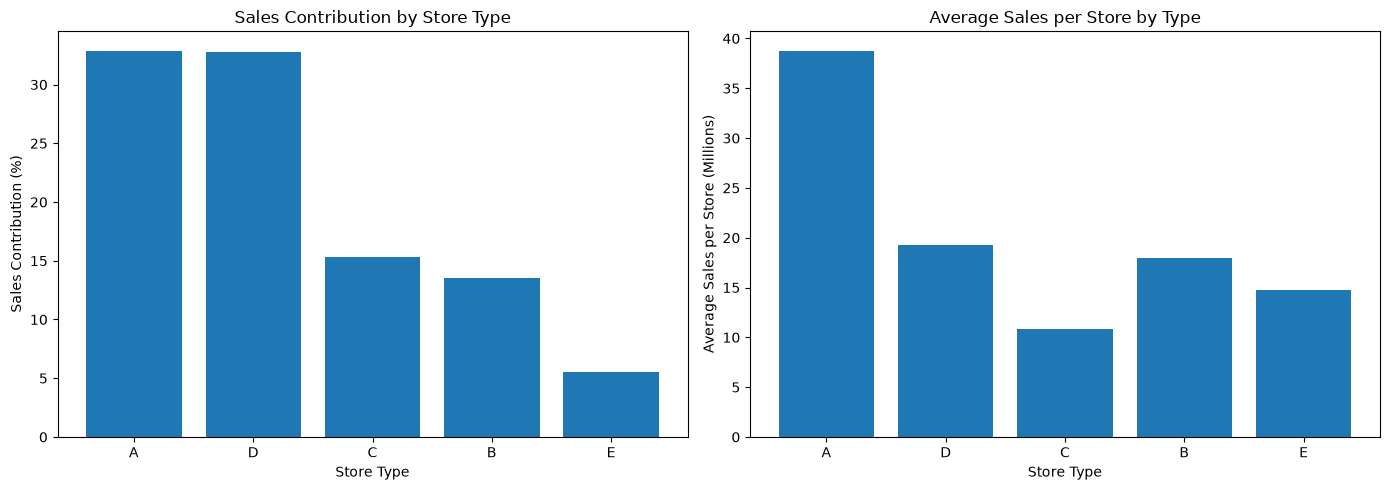

In [24]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Sales contribution.
axes[0].bar(
    store_type_performance["type"],
    store_type_performance["sales_share_pct"]
)

axes[0].set_title("Sales Contribution by Store Type")
axes[0].set_xlabel("Store Type")
axes[0].set_ylabel("Sales Contribution (%)")

# Chart 2: Average sales per store.
axes[1].bar(
    store_type_performance["type"],
    store_type_performance["avg_sales_per_store"] / 1_000_000
)

axes[1].set_title("Average Sales per Store by Type")
axes[1].set_xlabel("Store Type")
axes[1].set_ylabel("Average Sales per Store (Millions)")

plt.tight_layout()
plt.show()

## 18. City-Level Sales Performance

### Business Questions

1. Which cities generate the highest total sales?
2. How many stores operate in each city?
3. Which cities have the highest average sales per store?
4. How does promotion record share vary by city?

### Important Consideration

Cities with more stores may naturally generate
higher total sales.

Therefore, compare both total sales and
average sales per store.

In [25]:
city_performance = (
    store_analysis.groupby("city", as_index=False)
    .agg(
        number_of_stores=("store_nbr", "nunique"),
        total_sales=("total_sales", "sum"),
        total_records=("total_records", "sum"),
        promotional_records=("promotional_records", "sum")
    )
)

city_performance["avg_sales_per_store"] = (
    city_performance["total_sales"]
    / city_performance["number_of_stores"]
)

city_performance["sales_share_pct"] = (
    city_performance["total_sales"]
    / city_performance["total_sales"].sum()
    * 100
)

city_performance["promotion_record_share_pct"] = (
    city_performance["promotional_records"]
    / city_performance["total_records"]
    * 100
)

city_performance = (
    city_performance
    .sort_values("total_sales", ascending=False)
    .reset_index(drop=True)
)

display(city_performance.head(10).round(2))

,city,number_of_stores,total_sales,total_records,promotional_records,avg_sales_per_store,sales_share_pct,promotion_record_share_pct
0,Quito,18,5.508597e+08,991386,224474,30603315.98,51.91,22.64
1,Guayaquil,8,1.215147e+08,440616,86090,15189339.76,11.45,19.54
2,Cuenca,3,4.857742e+07,165231,33426,16192472.61,4.58,20.23
3,Ambato,2,3.988616e+07,110154,25272,19943082.30,3.76,22.94
4,Santo Domingo,3,3.537147e+07,165231,31449,11790491.63,3.33,19.03
5,Machala,2,3.292828e+07,110154,22782,16464141.14,3.10,20.68
6,Cayambe,1,2.800521e+07,55077,11329,28005209.16,2.64,20.57
7,Latacunga,2,2.096451e+07,110154,17662,10482253.49,1.98,16.03
8,Daule,1,1.896820e+07,55077,12382,18968202.65,1.79,22.48
9,Loja,1,1.867542e+07,55077,13138,18675424.53,1.76,23.85


## 19. City-Level Data Validation

### Objective

Confirm that city-level aggregation accurately reconciles
with store-level performance.

### Validation Rules

1. All 22 cities are represented.
2. Store counts reconcile to 54.
3. Total sales reconcile to source data.
4. Record counts reconcile.
5. Promotional record counts reconcile.
6. Sales contribution totals 100%.
7. Promotion record shares are within valid boundaries.

In [26]:
assert len(city_performance) == 22

assert (
    city_performance["number_of_stores"].sum()
    == 54
)

assert abs(
    city_performance["total_sales"].sum()
    - store_analysis["total_sales"].sum()
) < 0.01

assert (
    city_performance["total_records"].sum()
    == len(sales)
)

assert (
    city_performance["promotional_records"].sum()
    == sales["has_promotion"].sum()
)

assert abs(
    city_performance["sales_share_pct"].sum()
    - 100
) < 0.000001

assert city_performance[
    "promotion_record_share_pct"
].between(0, 100).all()

print("City-level performance validation passed.")

print(
    "Top 3 cities sales contribution (%):",
    round(
        city_performance.head(3)["sales_share_pct"].sum(),
        2
    )
)

City-level performance validation passed.
Top 3 cities sales contribution (%): 67.94


## 20. Top 10 Cities by Total Sales

### Business Objective

Visualize geographic sales concentration.

### Business Interpretation

Cities with more stores may contribute more sales.

Therefore, total city sales should be interpreted
alongside the number of stores and average sales
per store.

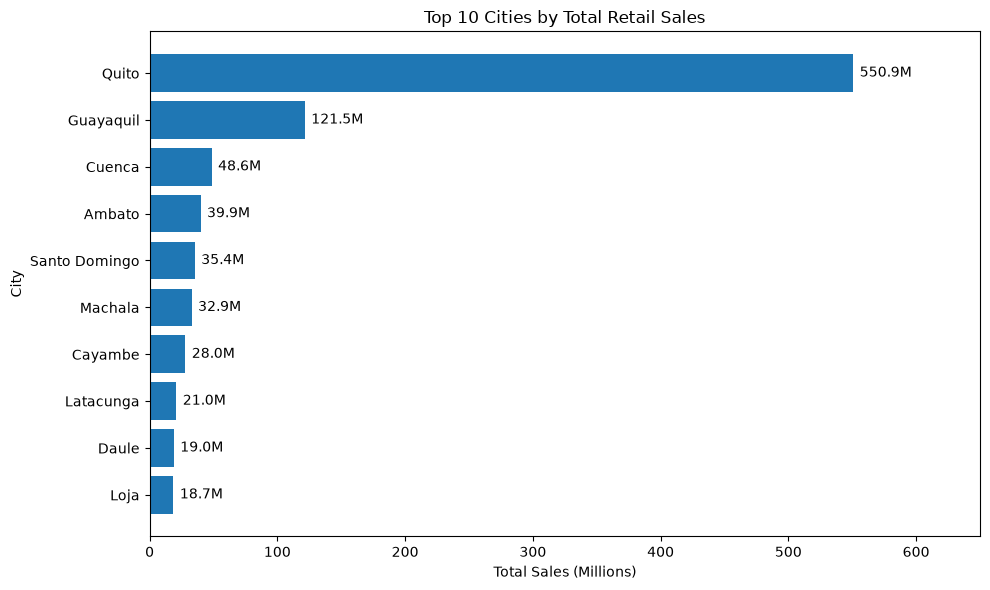

In [29]:
# Select top 10 cities.
top_cities = city_performance.head(10).copy()

# Convert sales to millions.
top_cities["sales_millions"] = (
    top_cities["total_sales"] / 1_000_000
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    top_cities["city"],
    top_cities["sales_millions"]
)

ax.invert_yaxis()

ax.set_title("Top 10 Cities by Total Retail Sales")
ax.set_xlabel("Total Sales (Millions)")
ax.set_ylabel("City")

# Add labels.
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 5,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}M",
        va="center"
    )

ax.set_xlim(
    0,
    top_cities["sales_millions"].max() * 1.18
)

plt.tight_layout()
plt.show()

## 21. Export Store-Level Analytical Reports

### Outputs

1. Store-level sales and promotion performance
2. Store-type performance
3. City-level performance
4. Active-month-adjusted store performance

### Data Governance

Reports are exported only after analytical
validation has passed.

All outputs use the same complete-month
analysis period: January 2013 – July 2017.

In [28]:
# Create output directory.
report_dir = (
    PROJECT_ROOT / "reports" / "retail_driver_analysis"
)

report_dir.mkdir(parents=True, exist_ok=True)

# Define output tables and filenames.
reports = {
    "store_sales_promotion_performance.csv": store_analysis,
    "store_type_performance.csv": store_type_performance,
    "city_sales_performance.csv": city_performance,
    "store_active_month_performance.csv": active_store_performance
}

# Export and verify each report.
for filename, dataframe in reports.items():

    output_path = report_dir / filename

    dataframe.to_csv(output_path, index=False)

    reloaded = pd.read_csv(output_path)

    assert len(reloaded) == len(dataframe)
    assert reloaded.columns.tolist() == dataframe.columns.tolist()

    print(f"Validated: {filename} ({len(reloaded)} rows)")

print("All four analytical reports exported successfully.")

Validated: store_sales_promotion_performance.csv (54 rows)
Validated: store_type_performance.csv (5 rows)
Validated: city_sales_performance.csv (22 rows)
Validated: store_active_month_performance.csv (54 rows)
All four analytical reports exported successfully.


## 22. Final Business Insights and Recommendations

### Analysis Scope

- Period: January 2013 to July 2017
- Sales records: 2,974,158
- Stores: 54
- Product families: 33
- Cities: 22
- Store types: 5
- Total sales: 1,061,211,629.26

### Key Findings

**1. Store Sales Concentration**

- Store 44 generated the highest sales: 61.47M.
- The top five stores contributed 24.38% of total sales.
- The top ten stores contributed 40.22%.

**2. Promotion Activity**

- Overall promotion record share: 20.16%.
- Store 46 had the highest full-history promotion record share: 26.99%.
- Full-history promotion–sales correlation: +0.728.

**3. Store Activity Adjustment**

- Store 52 first recorded positive sales on April 20, 2017.
- It had 51 months with zero recorded sales.
- Its promotion record share was 3.16% over the full history,
  compared with 43.17% during sales-active months.
- The active-month-adjusted correlation was +0.397.

**4. Store-Type Performance**

- Type A contributed 32.89% of sales across nine stores.
- Type D contributed 32.74% across eighteen stores.
- Type A had the highest average sales per store: 38.78M.

**5. Geographic Concentration**

- Quito contributed 51.91% of total sales.
- Guayaquil contributed 11.45%.
- Cuenca contributed 4.58%.
- The top three cities contributed 67.94%.

### Business Recommendations

1. Prioritize forecast monitoring for high-revenue stores and cities.
2. Account for store activity history when comparing performance.
3. Evaluate promotional activity alongside store type, location
   and product mix.
4. Investigate partial operating months before developing
   store-level forecasting models.
5. Use activity-adjusted metrics alongside full-history KPIs.

### Analytical Limitations

- Promotion counts do not represent discount percentages.
- Promotion–sales correlations do not establish causation.
- Observed sales activity does not confirm official opening dates.
- Average sales per active month does not fully adjust for
  partial-month exposure.
- Store-type codes have not been mapped to retail formats.
- Sales values are reported in dataset units without assuming
  a currency.

### Deliverables

- Store-level sales and promotion performance CSV
- Store-type performance CSV
- City-level sales performance CSV
- Active-month store performance CSV
- Validated Jupyter notebook with charts and analysis